# Figure 5. Independent model improvement validates FastRNA structural-quality measurements

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
GREEN, RED = "#4C72B0", "#DD8452"

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.022, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

RES = pd.read_csv(data_file("reference/resolved_again/resolve_per_molecule_points.csv"))
REDO = pd.read_csv(data_file("reference/resolved_again/redo_per_structure_points.csv"))
print(f"{len(RES)} molecules solved twice | {len(REDO):,} re-refined structures")

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


161 molecules solved twice | 1,521 re-refined structures


## Shared panel drawing


In [2]:
def outcome_label(w, b, better_is):
    d = (np.asarray(b, float) - np.asarray(w, float)) * better_is
    up, down = (d > 0).mean(), (d < 0).mean()
    better_word, worse_word = (("improved", "worse") if better_is > 0
                               else ("fewer", "more"))
    if up >= down:
        return f"{100 * up:.0f}% {better_word}", GREEN
    return f"{100 * down:.0f}% {worse_word}", RED

SIZES = {False: dict(s=18, s_pucker=16, head=10, count=7.5),
         True: dict(s=5, s_pucker=5, head=7, count=6)}

def _annotate(ax, txt, col, n, unit, compact=False):
    z = SIZES[compact]
    box = dict(boxstyle="round,pad=0.28", facecolor="white", edgecolor="none", alpha=0.8)
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, ha="left", va="top",
            fontsize=z["head"], color=col, weight="bold", zorder=5, bbox=box)
    if not compact:
        ax.text(0.04, 0.87, f"{n:,} {unit}", transform=ax.transAxes, ha="left", va="top",
                fontsize=z["count"], color="0.45", zorder=5, bbox=box)

def paired_panel(ax, w, b, *, better_is, title, ylabel, unit, drop_zero=False,
                 show_xlabel=True, show_ylabel=True, compact=False):
    d = pd.DataFrame({"w": w, "b": b}).dropna()
    if drop_zero:
        d = d[d.w > 0]
    w, b = d.w.to_numpy(), d.b.to_numpy()
    better = (b - w) * better_is > 0
    lo, hi = min(w.min(), b.min()), max(w.max(), b.max())
    pad = (hi - lo) * 0.06
    lo, hi = lo - pad, hi + pad

    txt, col = outcome_label(w, b, better_is)
    shade_up = (better_is > 0) if col == GREEN else (better_is < 0)
    ax.fill_between([lo, hi], [lo, hi], hi if shade_up else lo, color=col,
                    alpha=0.22, zorder=0, lw=0)
    ax.plot([lo, hi], [lo, hi], "--", color="0.45", lw=1.0, zorder=1)
    ax.scatter(w[better], b[better], s=SIZES[compact]["s"], facecolor=GREEN, edgecolor="0.15",
               linewidths=0.3, alpha=0.8, zorder=3)
    ax.scatter(w[~better], b[~better], s=SIZES[compact]["s"], facecolor=RED, edgecolor="0.15",
               linewidths=0.3, alpha=0.8, zorder=3)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    if better_is < 0:
        ax.invert_xaxis(); ax.invert_yaxis()
    ax.set_xlabel(f"{title[0].upper()}{title[1:]}\n(original)" if show_xlabel else "")
    ax.set_ylabel(ylabel if show_ylabel else "")
    _annotate(ax, txt, col, len(d), unit, compact)
    finish(ax)
    return len(d)

def pucker_panel(ax, w, b, *, ylabel, unit, show_xlabel=True, show_ylabel=True,
                 compact=False):
    d = pd.DataFrame({"w": w, "b": b}).dropna()
    d = d[d.w > 0]
    xr, yr = d.w.to_numpy(float), d.b.to_numpy(float)
    better = yr < xr
    hi = max(xr.max(), yr.max()) * 1.8
    txt, col = outcome_label(xr, yr, -1.0)
    ax.fill_between([0, hi], [0, hi], 0 if col == GREEN else hi, color=col,
                    alpha=0.22, lw=0, zorder=0)
    ax.plot([0, hi], [0, hi], "--", color="0.45", lw=1.0, zorder=1)
    rng = np.random.default_rng(0)
    jit = lambda v: v * (1 + rng.uniform(-0.06, 0.06, len(v)))
    ax.scatter(jit(xr)[better], jit(yr)[better], s=SIZES[compact]["s_pucker"], facecolor=GREEN,
               edgecolor="0.15", linewidths=0.3, alpha=0.8, zorder=3)
    ax.scatter(jit(xr)[~better], jit(yr)[~better], s=SIZES[compact]["s_pucker"], facecolor=RED,
               edgecolor="0.15", linewidths=0.3, alpha=0.8, zorder=3)
    ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
    ax.set_xlim(-0.25, hi); ax.set_ylim(-0.25, hi)
    ax.set_aspect("equal", adjustable="box")
    ticks = [t for t in (0, 1, 10, 100, 1000) if t <= hi]
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(mticker.FixedLocator(ticks))
        axis.set_minor_locator(mticker.NullLocator())
        axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v)}"))
    ax.invert_xaxis(); ax.invert_yaxis()
    ax.set_xlabel("Flagged riboses\n(original)" if show_xlabel else "")
    ax.set_ylabel(ylabel if show_ylabel else "")
    _annotate(ax, txt, col, len(d), unit, compact)
    finish(ax)
    return len(d)

RE_Y, REDO_Y = "re-solved", "PDB-REDO"


## Panel A
Base-pair quality-score changes in independently better-resolved models


111 units


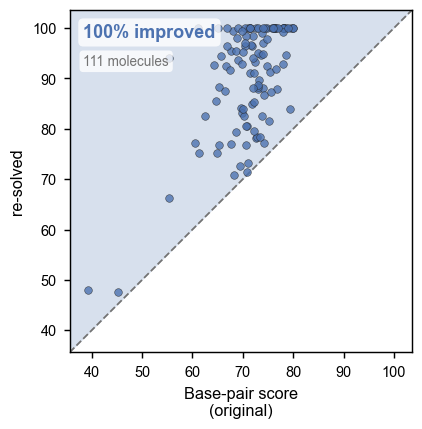

In [3]:
def draw_a(ax, **kw):
    return paired_panel(ax, RES.score_w, RES.score_b, better_is=+1,
                        title="base-pair score", ylabel=RE_Y, unit="molecules", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_a(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_A_resolved_pair_score.png")
plt.show()


## Panel B
Backbone-suiteness changes in independently better-resolved models


161 units


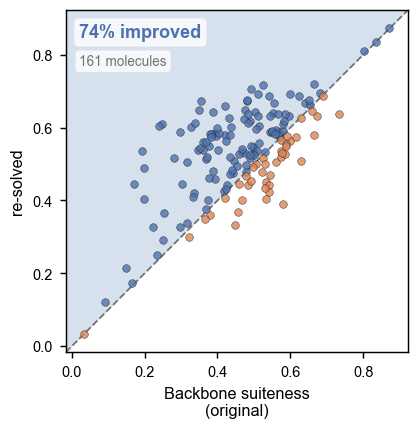

In [4]:
def draw_b(ax, **kw):
    return paired_panel(ax, RES.suit_w, RES.suit_b, better_is=+1,
                        title="backbone suiteness", ylabel=RE_Y, unit="molecules", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_b(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_B_resolved_suiteness.png")
plt.show()


## Panel C
Changes in unassigned backbone conformers in better-resolved models


159 units


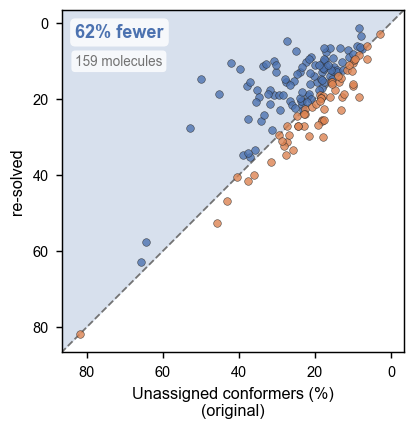

In [5]:
def draw_c(ax, **kw):
    return paired_panel(ax, RES.bang_w, RES.bang_b, better_is=-1,
                        title="unassigned conformers (%)", ylabel=RE_Y, unit="molecules",
                        drop_zero=True, **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_c(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_C_resolved_unassigned.png")
plt.show()


## Panel D
Changes in sugar-pucker flags in better-resolved models


33 units


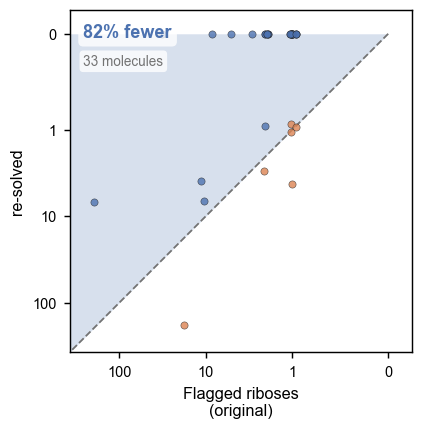

In [6]:
def draw_d(ax, **kw):
    return pucker_panel(ax, RES.puck_n_w, RES.puck_n_b, ylabel=RE_Y, unit="molecules", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_d(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_D_resolved_pucker.png")
plt.show()


## Panel E
Base-pair quality-score changes following PDB-REDO re-refinement


335 units


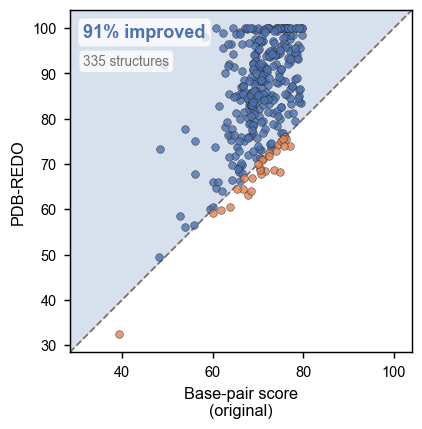

In [7]:
def draw_e(ax, **kw):
    return paired_panel(ax, REDO.score_o, REDO.score_r, better_is=+1,
                        title="base-pair score", ylabel=REDO_Y, unit="structures", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_e(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_E_redo_pair_score.png")
plt.show()


## Panel F
Backbone-suiteness changes following PDB-REDO re-refinement


1,521 units


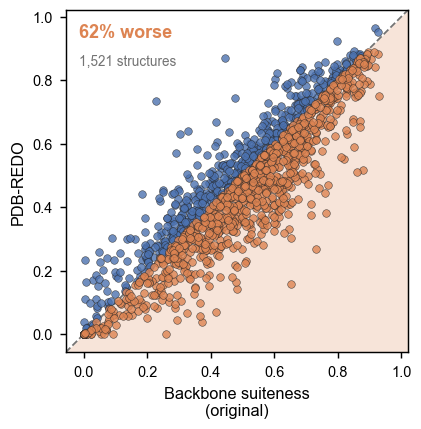

In [8]:
def draw_f(ax, **kw):
    return paired_panel(ax, REDO.suit_o, REDO.suit_r, better_is=+1,
                        title="backbone suiteness", ylabel=REDO_Y, unit="structures", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_f(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_F_redo_suiteness.png")
plt.show()


## Panel G
Changes in unassigned backbone conformers following PDB-REDO


1,190 units


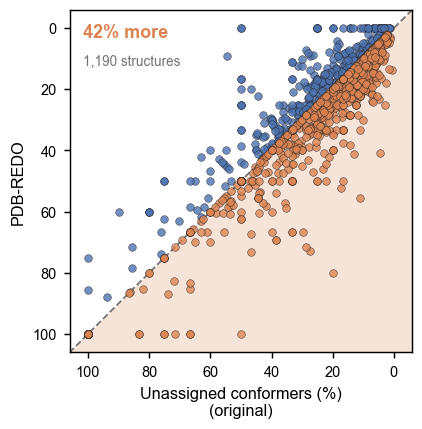

In [9]:
def draw_g(ax, **kw):
    return paired_panel(ax, REDO.bang_o, REDO.bang_r, better_is=-1,
                        title="unassigned conformers (%)", ylabel=REDO_Y, unit="structures",
                        drop_zero=True, **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_g(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_G_redo_unassigned.png")
plt.show()


## Panel H
Changes in sugar-pucker flags following PDB-REDO


183 units


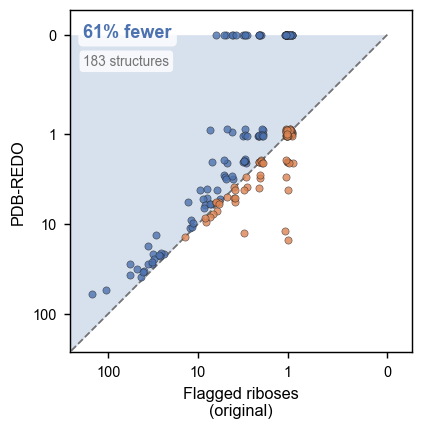

In [10]:
def draw_h(ax, **kw):
    return pucker_panel(ax, REDO.puck_n_o, REDO.puck_n_r, ylabel=REDO_Y, unit="structures", **kw)

fig, ax = plt.subplots(figsize=(3.4, 3.4))
print(f"{draw_h(ax):,} units")
fig.tight_layout()
save(fig, "figures/main/figure5_H_redo_pucker.png")
plt.show()


In [11]:
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch

IR = pd.read_csv(data_file("reference/resolved_again/issue_rates_per_unit.csv"))
IR["r_before"] = IR.n_before / IR.n_review
IR["r_after"] = IR.n_after / IR.n_review
for k, g in IR.groupby("cohort"):
    print(f"{k:9s} {g.unit.nunique():4d} units, "
          f"{g.groupby('unit').n_review.first().sum():,} Review-tier pairs")


pdb_redo   335 units, 2,169 Review-tier pairs
resolved   111 units, 1,103 Review-tier pairs


## Shared bar panel


In [12]:
ISSUE_DISPLAY = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                 "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                 "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                 "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}
DUMBBELL = "#4C72B0"
LEGEND_INK = DUMBBELL
SEEN_GREEN, SEEN_RED = GREEN, RED

def issue_rate_table(cohort):
    g = IR[IR.cohort == cohort]
    rate = g.groupby("issue")[["r_before", "r_after"]].mean().mul(100)
    rate["reduction"] = 100 * (rate.r_before - rate.r_after) / rate.r_before
    return rate

ROW_ORDER = issue_rate_table("pdb_redo").sort_values("reduction").index.tolist()

def issue_dumbbell(ax, cohort, after_label, unit_word, show_ylabel=True, compact=False):
    ms, mew, s = (3.5, 0.9, 12) if compact else (5, 1.1, 26)
    g = IR[IR.cohort == cohort]
    rate = issue_rate_table(cohort).loc[ROW_ORDER]
    y = np.arange(len(rate))
    o, r = rate.r_before.to_numpy(), rate.r_after.to_numpy()
    xmax = max(o.max(), r.max())

    col = np.where(r < o, SEEN_GREEN, SEEN_RED)
    ax.hlines(y, np.minimum(o, r), np.maximum(o, r), colors=col, lw=1.1, zorder=1)
    ax.scatter(o, y, s=s * 1.5, facecolor="white", edgecolor=col, linewidth=mew, zorder=2)
    ax.scatter(r, y, s=s * 1.85, facecolor=col, edgecolor="0.15", linewidth=0.3, zorder=3)
    for yi, oi, ri, red in zip(y, o, r, rate.reduction):
        ax.text(max(oi, ri) + xmax * 0.03, yi, f"{-red:+.0f}%", ha="left", va="center",
                fontsize=7, color="#404040")
    ax.set_yticks(y)
    if compact:
        ax.set_ylim(-0.7, len(rate) - 0.3)
    ax.set_yticklabels([ISSUE_DISPLAY.get(i, i) for i in rate.index] if show_ylabel else [])
    ax.set_xlim(0, xmax * 1.26)
    ax.set_xlabel("Priority-review pairs with the issue (%)")
    open_h = mlines.Line2D([], [], marker="o", linestyle="none", markersize=ms * 1.22,
                           markerfacecolor="white", markeredgecolor=LEGEND_INK,
                           markeredgewidth=mew, label="original")
    closed_h = mlines.Line2D([], [], marker="o", linestyle="none", markersize=ms * 1.36,
                             markerfacecolor=LEGEND_INK, markeredgecolor="0.15",
                             markeredgewidth=0.3, label=after_label)
    if compact:
        ax.legend(handles=[open_h, closed_h], loc="lower right", bbox_to_anchor=(1.0, 1.0),
                  ncol=2, handletextpad=0.1, handlelength=1.0, columnspacing=1.2,
                  borderaxespad=0.0, borderpad=0.0)
    else:
        ax.legend(handles=[open_h, closed_h], loc="upper right")
    finish(ax)
    return rate

def seat_legend(ax, gap_pt=0.5):
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    leg = ax.get_legend()
    lowest = min(h.get_window_extent(r).y0 for h in leg.legend_handles)
    for t in leg.get_texts():
        lowest = min(lowest, t.get_window_extent(r).y0)
    frame_top = (ax.get_window_extent(r).y1
                 + (ax.spines["top"].get_linewidth() / 2 + gap_pt) * fig.dpi / 72)
    dy = (lowest - frame_top) / ax.get_window_extent(r).height
    x, y = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted()).p0
    leg.set_bbox_to_anchor((x, y - dy), transform=ax.transAxes)


## Panel I
Changes in individual base-pair issues following PDB-REDO re-refinement


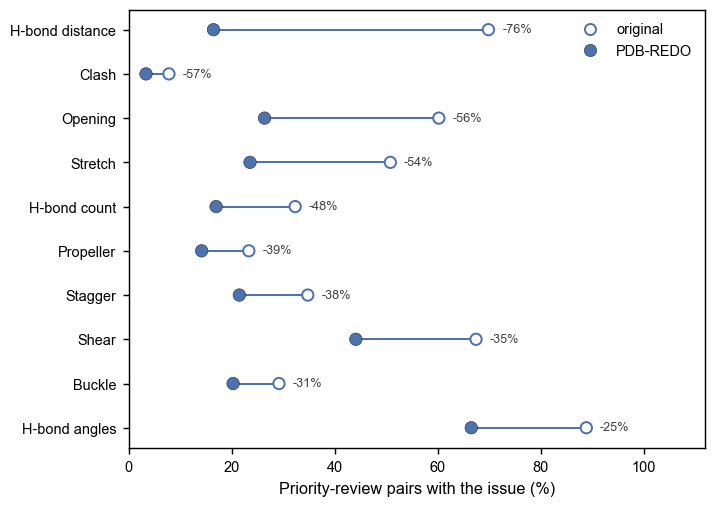

In [13]:
def draw_i(ax, **kw):
    return issue_dumbbell(ax, "pdb_redo", "PDB-REDO", "structures", **kw)

fig, ax = plt.subplots(figsize=(5.6, 4.0))
draw_i(ax)
fig.tight_layout()
save(fig, "figures/main/figure5_I_redo_issue_reduction.png")
plt.show()


## Panel J
Changes in individual base-pair issues in independently better-resolved structures


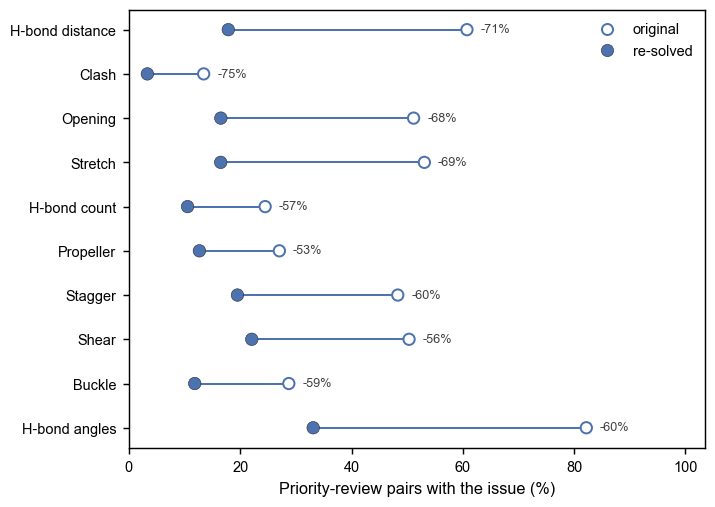

In [14]:
def draw_j(ax, **kw):
    return issue_dumbbell(ax, "resolved", "re-solved", "molecules", **kw)

fig, ax = plt.subplots(figsize=(5.6, 4.0))
draw_j(ax)
fig.tight_layout()
save(fig, "figures/main/figure5_J_resolved_issue_reduction.png")
plt.show()


## Shared render panel


In [15]:
from PIL import Image, ImageOps

RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

EXAMPLES = {"5C": ("4V2S", "Q", 11, 41), "5D": ("6ZDP", "B", 1296, 1322)}
REDO_PAIRS = json.loads(data_file("validation/pdb_redo_pairs_comparison.json").read_text())["pairs"]

def example_scores(stem):
    pdb, chain, a, b = EXAMPLES[stem]
    want = {(chain, str(a)), (chain, str(b))}
    for r in REDO_PAIRS:
        ids = {tuple(x.split("-")[::2]) for x in (r["res_id1"], r["res_id2"])}
        if r["pdb_id"].upper() == pdb and ids == want:
            return r["orig_score"], r["redo_score"]
    raise KeyError(f"{pdb} {chain}/{a}-{b} not in pdb_redo_pairs_comparison.json")

def content_box(name, thresh=246):
    im = Image.open(RENDERS / name).convert("RGB")
    return ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0).getbbox()

def autocrop(name, pad=8, thresh=246, box=None):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    box = box or content_box(name, thresh)
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst

RESOLVED = {"6D": ("6V3D", "7UVX", 1167, 1175)}
RESOLVED_PAIRS = pd.read_csv(data_file("reference/resolved_again/resolve_pairs_matched.csv"))

def resolved_scores(stem):
    worst, best, a, b = RESOLVED[stem]
    hit = RESOLVED_PAIRS[(RESOLVED_PAIRS.worst == worst) & (RESOLVED_PAIRS.best == best)
                         & (RESOLVED_PAIRS.num1 == str(a)) & (RESOLVED_PAIRS.num2 == str(b))]
    if len(hit) != 1:
        raise KeyError(f"{worst}->{best} {a}-{b} not in resolve_pairs_matched.csv")
    return worst, best, hit.score_w.iloc[0], hit.score_b.iloc[0]

def render_pair(ax_l, ax_r, stem, compact=False):
    if stem in RESOLVED:
        worst, best, orig, redo = resolved_scores(stem)
        sides = ((ax_l, "orig", "original", orig), (ax_r, "resolved", "re-solved", redo))
    else:
        orig, redo = example_scores(stem)
        sides = ((ax_l, "orig", "original", orig), (ax_r, "redo", "PDB-REDO", redo))
    boxes = None
    if stem in RESOLVED:
        bb = [content_box(f"{stem}_{tag}.png") for _, tag, _, _ in sides]
        x0, x1 = min(b[0] for b in bb), max(b[2] for b in bb)
        boxes = [(x0, b[1], x1, b[3]) for b in bb]
    for k, (ax, tag, label, score) in enumerate(sides):
        ax.imshow(plt.imread(autocrop(f"{stem}_{tag}.png", box=boxes[k] if boxes else None)))
        ax.set_xticks([]); ax.set_yticks([])
        for side in ("top", "right", "bottom", "left"):
            ax.spines[side].set_visible(False)
        text = (f"{label} (score {score:g})" if score == round(score)
                else f"{label} (score {score:.1f})")
        if compact:
            ax.set_xlabel(text, fontsize=8, color="0.25", labelpad=2)
        else:
            ax.set_title(text, loc="center", fontsize=8.5, color="0.25", pad=2)


def refinement_arrow(ax_l, ax_r):
    fig = ax_l.figure
    fig.canvas.draw_idle()
    left, right = ax_l.get_position(), ax_r.get_position()
    y = (left.y0 + left.y1) / 2
    x0 = left.x1 + 0.018
    x1 = right.x0 - 0.018
    arrow = FancyArrowPatch(
        (x0, y), (x1, y),
        transform=fig.transFigure,
        arrowstyle="-|>",
        mutation_scale=12,
        linewidth=1.1,
        color="0.35",
        shrinkA=0,
        shrinkB=0,
        clip_on=False,
    )
    fig.add_artist(arrow)
    return arrow


def refinement_arrow_axis(ax):
    ax.set_axis_off()
    ax.annotate(
        "",
        xy=(0.86, 0.50),
        xytext=(0.14, 0.50),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="-|>", mutation_scale=13, linewidth=1.15, color="0.35"),
    )

## Panel K
Representative atomic before-and-after refinement example 1


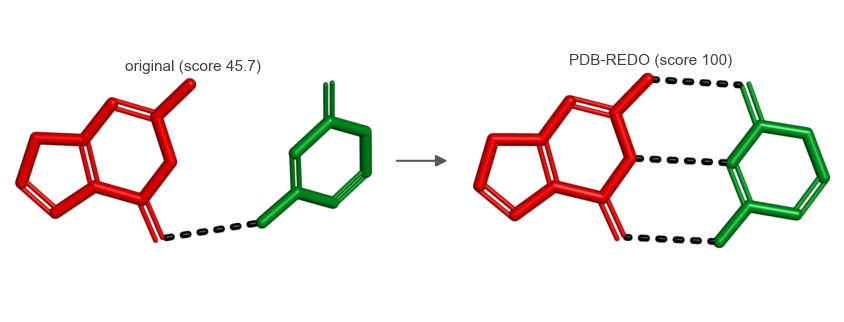

In [16]:
def draw_k(ax_l, ax_r, **kw):
    render_pair(ax_l, ax_r, "5C", **kw)

fig = plt.figure(figsize=(6.6, 2.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.22, 1],
                      left=0.02, right=0.98, top=0.88, bottom=0.08, wspace=0.02)
ax_l = fig.add_subplot(gs[0, 0])
ax_arrow = fig.add_subplot(gs[0, 1])
ax_r = fig.add_subplot(gs[0, 2])
draw_k(ax_l, ax_r)
refinement_arrow_axis(ax_arrow)
save(fig, "figures/main/figure5_K_example1.png")
plt.show()


## Panel L
Representative atomic before-and-after refinement example 2


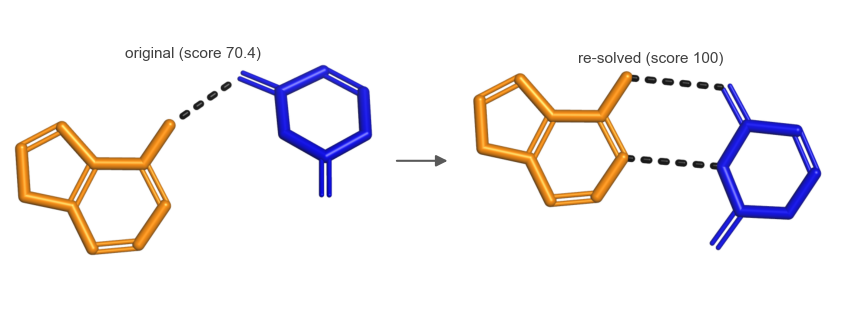

In [17]:
def draw_l(ax_l, ax_r, **kw):
    render_pair(ax_l, ax_r, "6D", **kw)

fig = plt.figure(figsize=(6.6, 2.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.22, 1],
                      left=0.02, right=0.98, top=0.88, bottom=0.08, wspace=0.02)
ax_l = fig.add_subplot(gs[0, 0])
ax_arrow = fig.add_subplot(gs[0, 1])
ax_r = fig.add_subplot(gs[0, 2])
draw_l(ax_l, ax_r)
refinement_arrow_axis(ax_arrow)
save(fig, "figures/main/figure5_L_example2.png")
plt.show()


## Combined figure


A: n = 111 molecules
B: n = 161 molecules
C: n = 159 molecules
D: n = 33 molecules
E: n = 335 structures
F: n = 1,521 structures
G: n = 1,190 structures
H: n = 183 structures


axis titles print at 8.5 pt and panel letters at 12.0 pt (8.31 in saved, shown at 6.73 in)


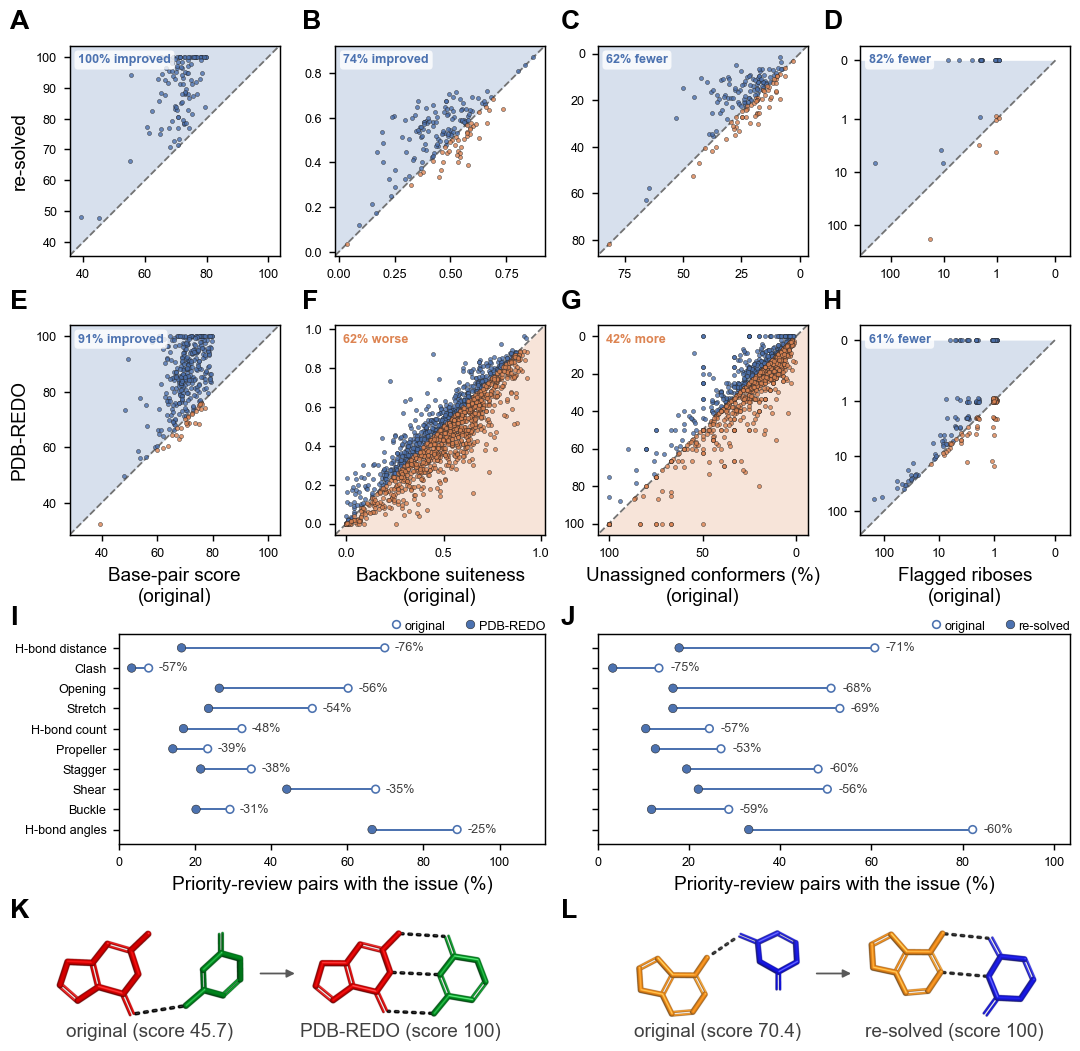

In [18]:
PANEL_IN = 1.615
FIG_W, FIG_H = 8.6, 4.97 + 5.5
ROW_TOP = (0.32, 0.32 + PANEL_IN + 0.64)
fig = plt.figure(figsize=(FIG_W, FIG_H))
gs = fig.add_gridspec(2, 4, left=0.08, right=0.99, top=0.95, bottom=0.16)
draws = [draw_a, draw_b, draw_c, draw_d, draw_e, draw_f, draw_g, draw_h]
axes = {}
for i, draw in enumerate(draws):
    row, col = divmod(i, 4)
    ax = fig.add_subplot(gs[row, col])
    n = draw(ax, show_xlabel=(row == 1), show_ylabel=(col == 0), compact=True)
    axes[(row, col)] = ax
    print(f"{'ABCDEFGH'[i]}: n = {n:,} {'molecules' if row == 0 else 'structures'}")

for (row, col), ax in axes.items():
    p = ax.get_position()
    ax.set_position([p.x0, 1 - (ROW_TOP[row] + PANEL_IN) / FIG_H,
                     PANEL_IN / FIG_W, PANEL_IN / FIG_H])

MARGIN_L, MARGIN_R = 0.012, 0.988
inv = fig.transFigure.inverted()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
span = lambda ax: ax.get_tightbbox(renderer).transformed(inv)
col_w = [max(span(axes[(r, c)]).width for r in range(2)) for c in range(4)]
gap = 0.12 / FIG_W
for c in range(4):
    x = MARGIN_L + sum(col_w[:c]) + gap * c
    for r in range(2):
        ax = axes[(r, c)]
        right = span(ax).x1
        p = ax.get_position()
        ax.set_position([p.x0 + (x + col_w[c]) - right, p.y0, p.width, p.height])
for c in range(4):
    x0 = max(axes[(r, c)].get_position().x0 for r in range(2))
    for r in range(2):
        p = axes[(r, c)].get_position()
        axes[(r, c)].set_position([x0, p.y0, p.width, p.height])


X_RIGHT = axes[(1, 3)].get_position().x1
IJ_GAP_IN = 0.12
ROW3_TOP = ROW_TOP[1] + PANEL_IN + 0.9
ax_i = fig.add_axes([0, 0, 0.1, 0.1]); ax_j = fig.add_axes([0, 0, 0.1, 0.1])
draw_i(ax_i, compact=True)
draw_j(ax_j, show_ylabel=False, compact=True)
for ax in (ax_i, ax_j):
    ax.set_position([0.3, 1 - (ROW3_TOP + PANEL_IN) / FIG_H, 2.3 / FIG_W, PANEL_IN / FIG_H])
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
lab = ax_i.get_position().x0 - span(ax_i).x0
w = (X_RIGHT - MARGIN_L - lab - IJ_GAP_IN / FIG_W) / 2
y0 = 1 - (ROW3_TOP + PANEL_IN) / FIG_H
e, f_, g, h_ = (axes[(1, k)].get_position() for k in range(4))
i_left = span(axes[(1, 0)]).x0 + lab
ax_i.set_position([i_left, y0, f_.x1 - i_left, PANEL_IN / FIG_H])
ax_j.set_position([g.x0, y0, h_.x1 - g.x0, PANEL_IN / FIG_H])

ARROW_IN = 0.5
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
e, f_, g, h_ = (axes[(1, k)].get_position() for k in range(4))
spans_kl = [(span(axes[(1, 0)]).x0 * FIG_W, f_.x1 * FIG_W), (g.x0 * FIG_W, h_.x1 * FIG_W)]
top = ROW3_TOP + PANEL_IN + 0.9
render_pairs, widths = [], []
for draw, (x0, x1) in zip((draw_k, draw_l), spans_kl):
    rw = (x1 - x0 - ARROW_IN) / 2
    ax_l = fig.add_axes(inch(x0, top, rw, 1.0))
    ax_r = fig.add_axes(inch(x1 - rw, top, rw, 1.0))
    draw(ax_l, ax_r, compact=True)
    render_pairs.append((ax_l, ax_r)); widths.append(rw)
RENDER_H_MAX = 0.7
h = min(RENDER_H_MAX, max(rw * a.images[0].get_array().shape[0] / a.images[0].get_array().shape[1]
                          for (pair, rw) in zip(render_pairs, widths) for a in pair))
aspect = lambda a: a.images[0].get_array().shape[1] / a.images[0].get_array().shape[0]
for (ax_l, ax_r), (x0, x1) in zip(render_pairs, spans_kl):
    xc = (x0 + x1) / 2
    wl, wr = h * aspect(ax_l), h * aspect(ax_r)
    ax_l.set_position(inch(xc - ARROW_IN / 2 - wl, top, wl, h))
    ax_r.set_position(inch(xc + ARROW_IN / 2, top, wr, h))

fig.canvas.draw()
r_ = fig.canvas.get_renderer()
for ax_l, ax_r in render_pairs:
    el = ax_l.images[0].get_window_extent(r_).transformed(inv)
    er = ax_r.images[0].get_window_extent(r_).transformed(inv)
    xm = (el.x1 + er.x0) / 2
    ym = ((el.y0 + el.y1) / 2 + (er.y0 + er.y1) / 2) / 2
    half_a = 0.32 * ARROW_IN / FIG_W
    fig.add_artist(FancyArrowPatch((xm - half_a, ym), (xm + half_a, ym), transform=fig.transFigure,
                                   arrowstyle="-|>", mutation_scale=9, linewidth=1.0,
                                   color="0.35"))

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
col_x = [min(span(axes[(r, c)]).x0 for r in range(2)) for c in range(4)]
for (row, col), ax in axes.items():
    fig.text(col_x[col], ax.get_position().y1 + 0.018 * 4.97 / FIG_H, "ABCDEFGH"[row * 4 + col],
             fontsize=12, fontweight="bold", ha="left", va="bottom")
for ax, s in ((ax_i, "I"), (ax_j, "J")):
    x = col_x[0] if ax is ax_i else col_x[2]
    fig.text(x, ax.get_position().y1 + 0.03 / FIG_H, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")
img_top = max(a.images[0].get_window_extent(renderer).transformed(inv).y1
              for pair in render_pairs for a in pair)
for (ax_l, ax_r), s in zip(render_pairs, "KL"):
    fig.text(col_x[0] if s == "K" else col_x[2], img_top + 0.004, s, fontsize=12,
             fontweight="bold", ha="left", va="bottom")

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)

ROW_GAP_IN = 0.10


def restack_rows(fig, rows, gap_in=ROW_GAP_IN, margin_in=0.05, extras=()):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    deltas, cursor = [], margin_in
    for top, bot in zip(tops, bots):
        deltas.append(cursor - top)
        cursor += bot - top + gap_in
    H2 = cursor - gap_in + margin_in
    for a, i in extras:
        H2 = max(H2, H - a.get_position(original=True).y0 * H + deltas[i] + margin_in)
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2

    def move(a, d):
        p = a.get_position(original=True)
        a.set_position([p.x0, conv(p.y0, d), p.width, p.height * H / H2], which="both")

    for i, row in enumerate(rows):
        for a in row:
            move(a, deltas[i])
    for a, i in extras:
        move(a, deltas[i])
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))
    for art in fig.artists:
        if hasattr(art, "_posA_posB") and art._posA_posB:
            (xa, ya), (xb, yb) = art._posA_posB
            d = deltas[row_of(H - ya * H)]
            art.set_positions((xa, conv(ya, d)), (xb, conv(yb, d)))

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
dx = span(axes[(1, 0)]).x0 - span(ax_i).x0
p_i = ax_i.get_position()
ax_i.set_position([p_i.x0 + dx, p_i.y0, p_i.width - dx, p_i.height])

restack_rows(fig, [[axes[(0, c)] for c in range(4)], [axes[(1, c)] for c in range(4)],
                   [ax_i, ax_j], [a for pair in render_pairs for a in pair]])
for ax in (ax_i, ax_j):
    seat_legend(ax)
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/main/figure5.png")
plt.show()
